# Multimodal Authentication & Product Recommendation System

Formative 2 — one section per rubric criterion. **Only edit your own section** and clear large outputs before pushing.

| Section | Owner |
|---|---|
| §1 Tabular EDA · §2 Cleaning, merge & product model | Kethia (tabular lead) |
| §3 Image data, augmentation & face model | Tabitha (image lead) |
| §4 Audio data, augmentation & voice model | Towi (audio lead) |
| §5 Multimodal logic, thresholds & system simulation | Harmony (integration lead) |

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else str(Path.cwd() / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, kruskal

import config
import data_merge as dm
import product_model as pm

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# one fixed colour per product category, used in every chart
CATEGORIES = ["Books", "Clothing", "Electronics", "Groceries", "Sports"]
CAT_COLORS = dict(zip(CATEGORIES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
BLUE = "#2a78d6"

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight")

---
# §1 Exploratory Data Analysis (tabular)

Two sources: **customer_social_profiles** (one row per customer × platform review) and **customer_transactions** (one row per purchase). The goal is a model that predicts `product_category` for a customer visiting our social media.

## 1.1 Raw data overview

In [2]:
social_raw, txn_raw = dm.load_raw()
for name, df in [("social", social_raw), ("transactions", txn_raw)]:
    print(f"== {name}: {df.shape[0]} rows x {df.shape[1]} columns")
    display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(),
                          "unique": df.nunique()}))
    display(df.head())

== social: 155 rows x 5 columns


,dtype,missing,unique
customer_id_new,str,0,84
social_media_platform,str,0,5
engagement_score,int64,0,50
purchase_interest_score,float64,0,40
review_sentiment,str,0,3


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


== transactions: 150 rows x 6 columns


,dtype,missing,unique
customer_id_legacy,int64,0,75
transaction_id,int64,0,150
purchase_amount,int64,0,120
purchase_date,datetime64[us],0,150
product_category,str,0,5
customer_rating,float64,10,37


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


In [3]:
quality = pd.DataFrame({
    "rows": [len(social_raw), len(txn_raw)],
    "exact duplicate rows": [social_raw.duplicated().sum(), txn_raw.duplicated().sum()],
    "missing values": [social_raw.isna().sum().sum(), txn_raw.isna().sum().sum()],
    "unique customers": [social_raw["customer_id_new"].nunique(), txn_raw["customer_id_legacy"].nunique()],
    "customer ID format": [social_raw["customer_id_new"].iloc[0], txn_raw["customer_id_legacy"].iloc[0]],
}, index=["social", "transactions"])
quality

,rows,exact duplicate rows,missing values,unique customers,customer ID format
social,155,5,0,84,A178
transactions,150,0,10,75,151


**What this shows.** Social has 5 exact duplicate rows and transactions has 10 missing `customer_rating` values; nothing else is missing. The two tables use **different ID formats** (`"A178"` vs `178`), so they cannot be joined until the `"A"` prefix is stripped. Both tables have several rows per customer, which matters for the merge (§2.2).

## 1.2 Target: product category balance

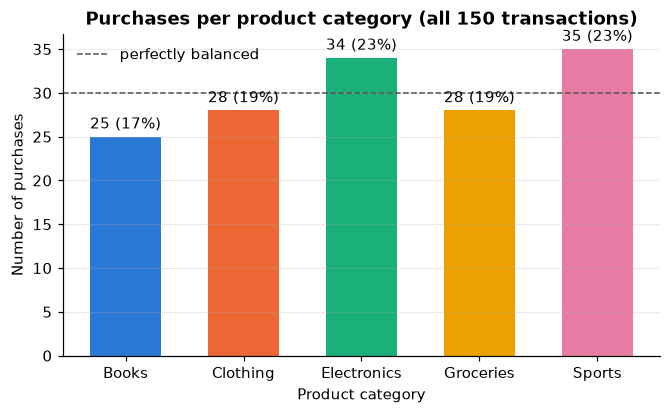

In [4]:
counts = txn_raw["product_category"].value_counts().reindex(CATEGORIES)
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(counts.index, counts.values, color=[CAT_COLORS[c] for c in counts.index], width=0.6)
ax.bar_label(bars, labels=[f"{v} ({v/counts.sum():.0%})" for v in counts.values], padding=3)
ax.axhline(counts.sum() / len(counts), color="#52514e", ls="--", lw=1, label="perfectly balanced")
ax.set(title="Purchases per product category (all 150 transactions)",
       xlabel="Product category", ylabel="Number of purchases")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
save(fig, "tab_01_target_balance"); plt.show()

**Interpretation.** The five classes are roughly balanced: Sports is the largest at 23% and Books the smallest at 17%. That means **always guessing "Sports" scores about 23% accuracy**, and random guessing scores 20%. Any model has to clearly beat those numbers before it counts as useful. The balance also means we don't need resampling or class weights.

## 1.3 Distributions of the numeric features

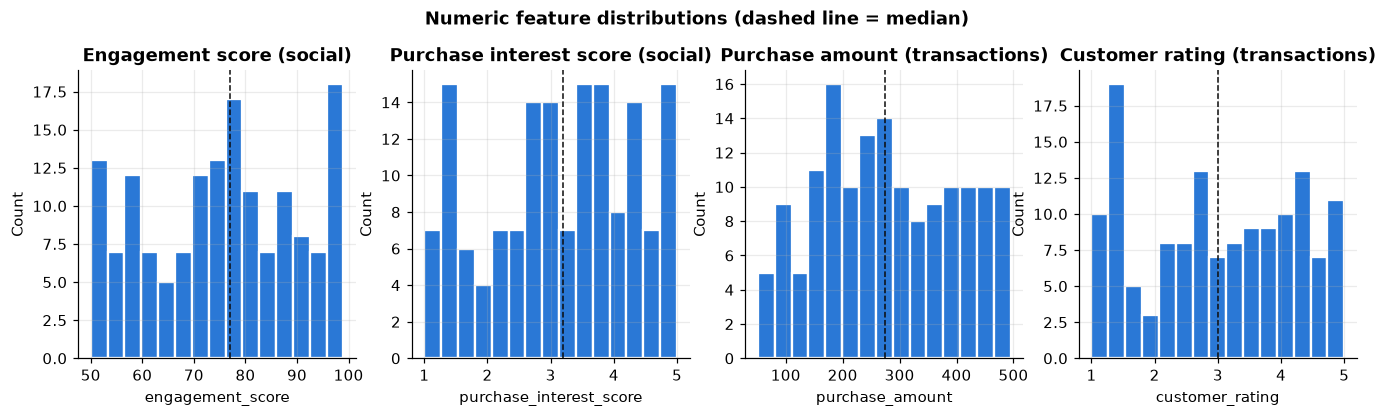

,purchase_amount,customer_rating,engagement_score,purchase_interest_score
count,150.00,140.00,155.00,155.00
mean,280.78,2.98,75.61,3.15
std,121.33,1.21,14.57,1.14
min,51.00,1.00,50.00,1.00
25%,179.00,1.95,63.50,2.35
50%,274.00,3.00,77.00,3.20
75%,388.50,4.00,87.50,4.10
max,495.00,5.00,99.00,5.00


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
specs = [(social_raw, "engagement_score", "Engagement score (social)"),
         (social_raw, "purchase_interest_score", "Purchase interest score (social)"),
         (txn_raw, "purchase_amount", "Purchase amount (transactions)"),
         (txn_raw, "customer_rating", "Customer rating (transactions)")]
for ax, (df, col, label) in zip(axes, specs):
    ax.hist(df[col].dropna(), bins=15, color=BLUE, edgecolor="white", linewidth=1.5)
    ax.axvline(df[col].median(), color="#0b0b0b", ls="--", lw=1)
    ax.set(title=label, xlabel=col, ylabel="Count")
fig.suptitle("Numeric feature distributions (dashed line = median)", y=1.04, fontweight="bold")
save(fig, "tab_02_numeric_distributions"); plt.show()
txn_raw[["purchase_amount", "customer_rating"]].describe().join(
    social_raw[["engagement_score", "purchase_interest_score"]].describe()).round(2)

**Interpretation.** All four features are spread almost **uniformly** across their ranges (engagement 50–99, interest 1–5, amount 51–495, rating 1–5) with no long tails or extreme outliers. So no outlier removal or log-transform is needed, and standard scaling is enough. A flat, uniform shape like this is also typical of **synthetically generated** data, which is a first hint that the features may carry little real signal.

## 1.4 Summary statistics and outlier check

Categorical columns


,customer_id_new,social_media_platform,review_sentiment,product_category
count,155,155,155,150
unique,84,5,3,5
top,A155,Twitter,Positive,Sports
freq,7,38,63,35


Numeric columns + outlier check


,mean,std,min,max,skew,IQR lower fence,IQR upper fence,outliers (1.5xIQR)
engagement_score,75.61,14.57,50.0,99.0,-0.11,27.50,123.50,0.0
purchase_interest_score,3.15,1.14,1.0,5.0,-0.23,-0.28,6.72,0.0
purchase_amount,280.78,121.33,51.0,495.0,0.06,-135.25,702.75,0.0
customer_rating,2.98,1.21,1.0,5.0,-0.08,-1.12,7.07,0.0


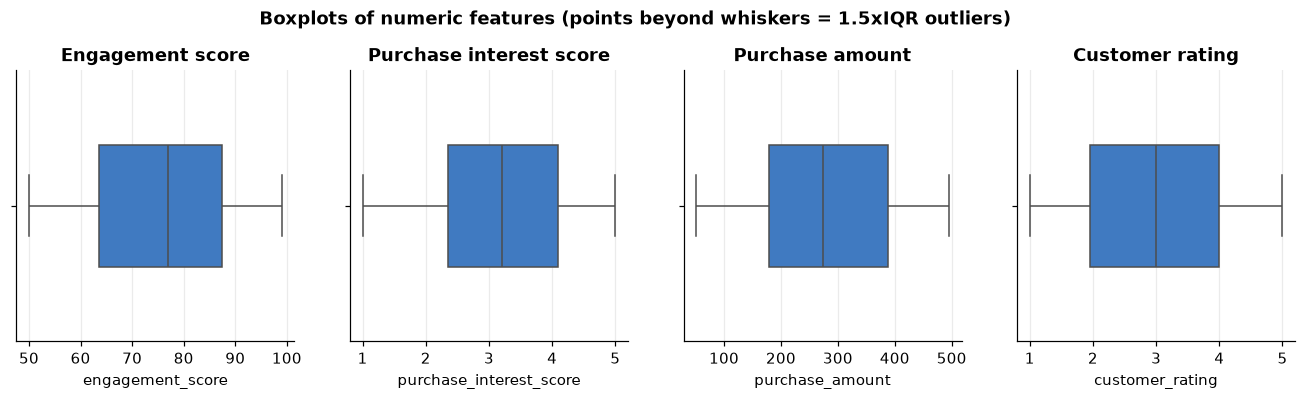

In [6]:
print("Categorical columns")
display(pd.concat([social_raw.describe(exclude="number"), txn_raw[["product_category"]].describe(exclude="number")], axis=1))
num_cols = {"engagement_score": social_raw, "purchase_interest_score": social_raw,
            "purchase_amount": txn_raw, "customer_rating": txn_raw}
rows = {}
for col, df in num_cols.items():
    x = df[col].dropna(); q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows[col] = {"mean": x.mean(), "std": x.std(), "min": x.min(), "max": x.max(), "skew": x.skew(),
                 "IQR lower fence": lo, "IQR upper fence": hi, "outliers (1.5xIQR)": int(((x < lo) | (x > hi)).sum())}
print("Numeric columns + outlier check")
display(pd.DataFrame(rows).T.round(2))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (col, df) in zip(axes, num_cols.items()):
    sns.boxplot(x=df[col].dropna(), ax=ax, color=BLUE, width=0.45)
    ax.set(title=col.replace("_", " ").capitalize(), xlabel=col, ylabel="")
fig.suptitle("Boxplots of numeric features (points beyond whiskers = 1.5xIQR outliers)", y=1.05, fontweight="bold")
save(fig, "tab_03b_outlier_boxplots"); plt.show()

**Interpretation.** No numeric column has a single value beyond the 1.5×IQR fences, so no boxplot shows points past its whiskers. Every value also falls in a sensible range (scores 1–5 or 50–99, amounts 51–495). Skew is close to 0 for all four columns (between −0.23 and 0.06), so the distributions are symmetric. **No outliers need removing or capping**, and the only cleaning these columns need is the 10 missing ratings.

## 1.4b Social platforms and review sentiment

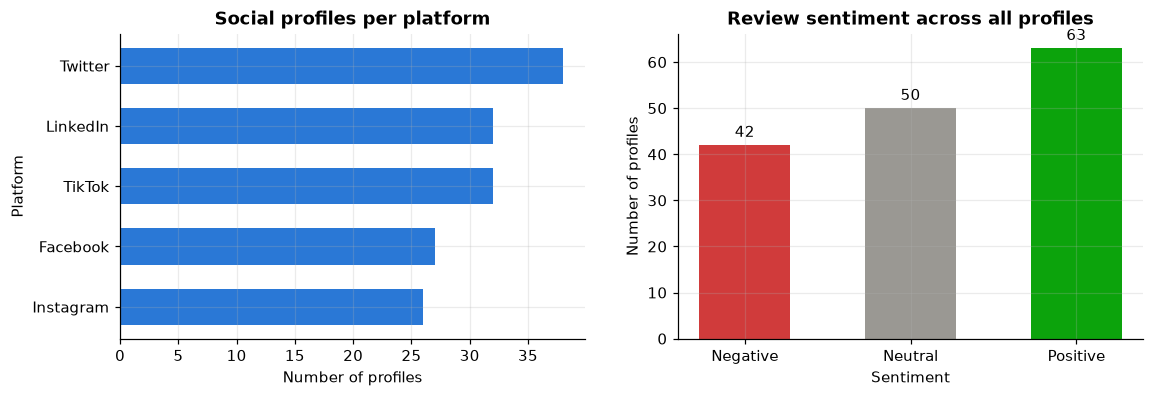

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plat = social_raw["social_media_platform"].value_counts()
axes[0].barh(plat.index[::-1], plat.values[::-1], color=BLUE, height=0.6)
axes[0].set(title="Social profiles per platform", xlabel="Number of profiles", ylabel="Platform")
sent = social_raw["review_sentiment"].value_counts().reindex(["Negative", "Neutral", "Positive"])
axes[1].bar(sent.index, sent.values, color=["#d03b3b", "#9a9893", "#0ca30c"], width=0.55)
axes[1].bar_label(axes[1].containers[0], padding=3)
axes[1].set(title="Review sentiment across all profiles", xlabel="Sentiment", ylabel="Number of profiles")
save(fig, "tab_03_platform_sentiment"); plt.show()

**Interpretation.** Customers are spread over all five platforms, with Twitter the most common (38 profiles) and Instagram the least (26), so no single platform dominates. Sentiment leans slightly positive (63 positive vs 42 negative). Both are categorical, so they get one-hot encoded (platform) or mapped to a −1/0/+1 score (sentiment) during feature engineering.

## 1.5 Rows per customer and ID overlap

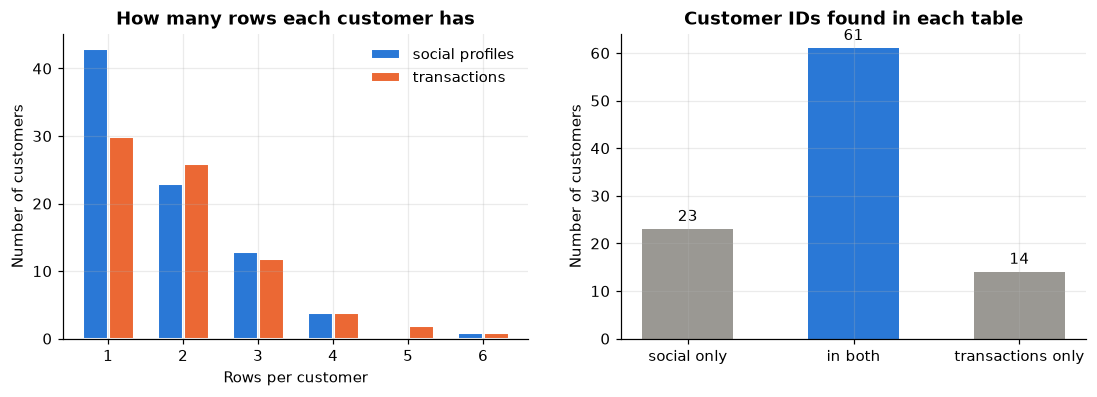

In [8]:
s_ids = set(social_raw["customer_id_new"].str.lstrip("A").astype(int))
t_ids = set(txn_raw["customer_id_legacy"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
per = pd.DataFrame({
    "social profiles": social_raw.drop_duplicates().groupby("customer_id_new").size().value_counts(),
    "transactions": txn_raw.groupby("customer_id_legacy").size().value_counts(),
}).fillna(0).astype(int).sort_index()
per.plot.bar(ax=axes[0], color=[BLUE, "#eb6834"], width=0.7, rot=0, edgecolor="white", linewidth=2)
axes[0].set(title="How many rows each customer has", xlabel="Rows per customer",
            ylabel="Number of customers")
axes[0].legend(frameon=False)
overlap = pd.Series({"social only": len(s_ids - t_ids), "in both": len(s_ids & t_ids),
                     "transactions only": len(t_ids - s_ids)})
b = axes[1].bar(overlap.index, overlap.values, color=["#9a9893", BLUE, "#9a9893"], width=0.55)
axes[1].bar_label(b, padding=3)
axes[1].set(title="Customer IDs found in each table", xlabel="", ylabel="Number of customers")
save(fig, "tab_04_rows_per_customer_overlap"); plt.show()

**Interpretation.** Many customers have more than one social profile (up to 6) and more than one purchase (up to 6). Joining the raw tables directly would therefore **duplicate purchases**, so social must be collapsed to one row per customer first (§2.2). Only **61 customers appear in both tables**, which caps how much data has both social and purchase information.

## 1.6 Do the features differ by product category?

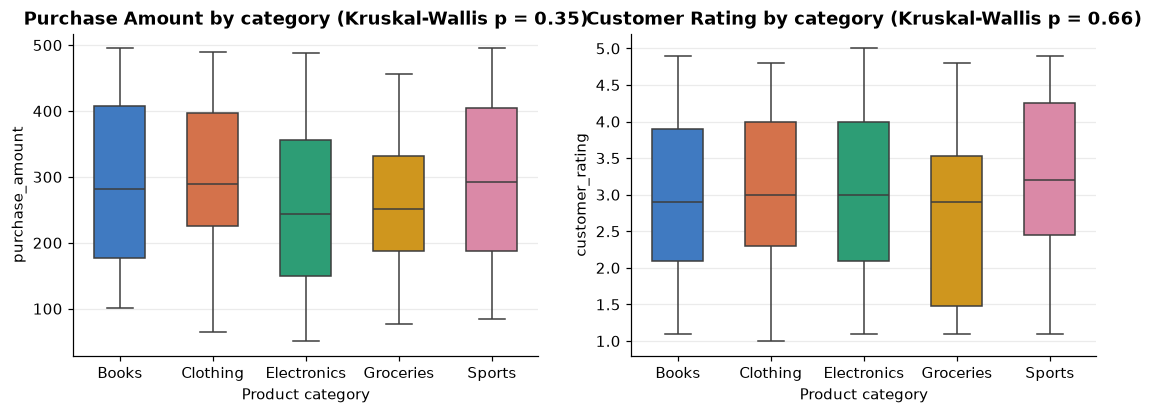

In [9]:
cleaned = dm.clean_transactions(txn_raw)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col in zip(axes, ["purchase_amount", "customer_rating"]):
    sns.boxplot(data=cleaned, x="product_category", y=col, order=CATEGORIES, hue="product_category",
                palette=CAT_COLORS, ax=ax, width=0.55, legend=False)
    p = kruskal(*[g[col] for _, g in cleaned.groupby("product_category")]).pvalue
    ax.set(title=f"{col.replace('_', ' ').title()} by category (Kruskal-Wallis p = {p:.2f})",
           xlabel="Product category", ylabel=col)
save(fig, "tab_05_amount_rating_by_category"); plt.show()

**Interpretation.** The boxes for every category overlap almost completely. Median spend runs from about 243 (Electronics) to 292 (Sports), and the Kruskal-Wallis tests (p = 0.35 for amount, p = 0.66 for rating) find **no significant difference** between categories. So how much a customer spends or how they rate a purchase tells us almost nothing about *what* they bought.

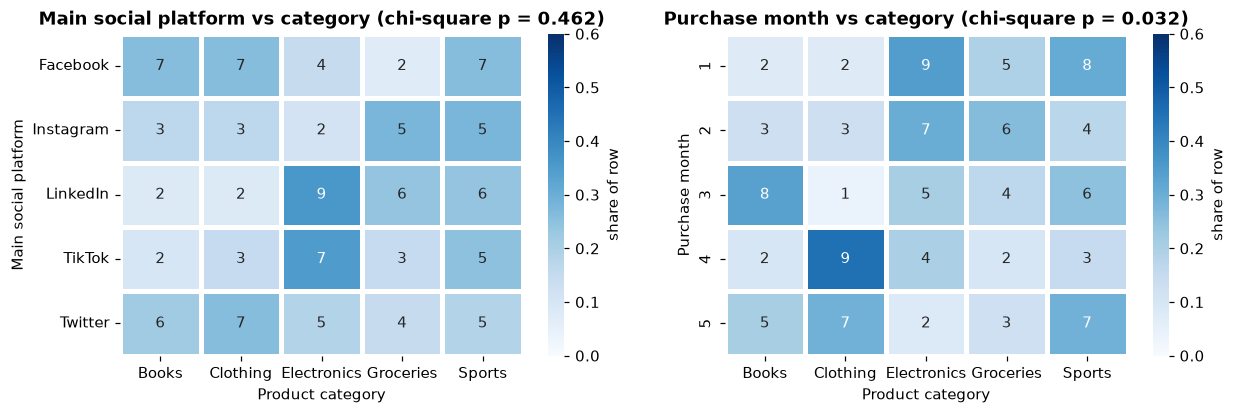

In [10]:
merged = pd.read_csv(config.MERGED_CSV, keep_default_na=False, na_values=[""])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col, title in [(axes[0], "top_platform", "Main social platform"),
                       (axes[1], "purchase_month", "Purchase month")]:
    ct = pd.crosstab(merged[col], merged["product_category"])
    p = chi2_contingency(ct)[1]
    sns.heatmap(ct.div(ct.sum(axis=1), axis=0), annot=ct, fmt="d", cmap="Blues", vmin=0, vmax=0.6,
                cbar_kws={"label": "share of row"}, ax=ax, linewidths=2, linecolor="white")
    ax.set(title=f"{title} vs category (chi-square p = {p:.3f})", xlabel="Product category", ylabel=title)
    ax.grid(False)
save(fig, "tab_06_category_crosstabs"); plt.show()

**Interpretation.** Each cell shows how many purchases fall in that combination, and the colour shows the share of the row. A customer's main platform shows **no relationship** with category (p = 0.46). Purchase month is the only feature with a weak pattern (p = 0.03, e.g. 9 of 20 April purchases were Clothing). But with only about 20 purchases per month and many tests run, this could easily be chance, so we treat it as a hint and not a finding.

## 1.7 Correlation between engineered numeric features

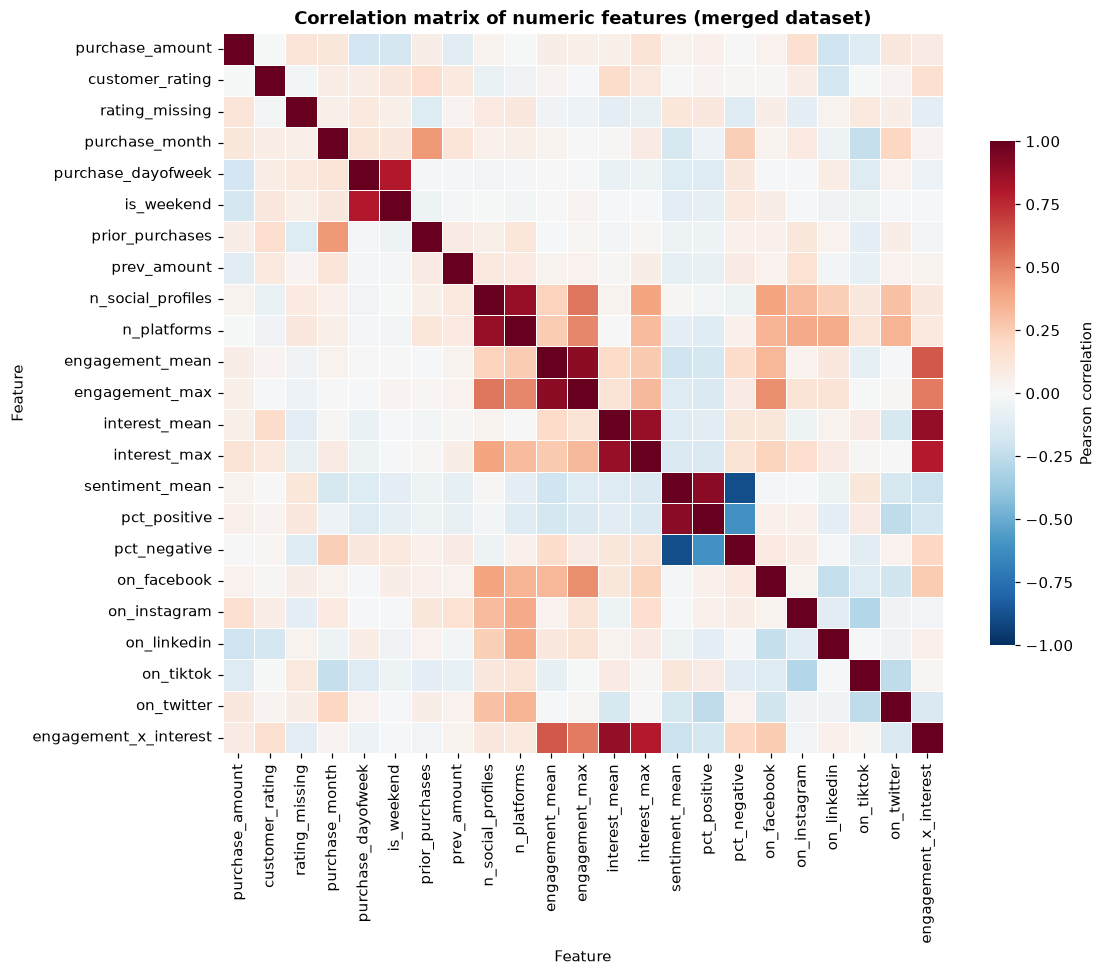

In [11]:
num = merged.select_dtypes("number").drop(columns=["customer_id", "transaction_id"])
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(num.corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Pearson correlation", "shrink": 0.7}, linewidths=0.5, linecolor="white")
ax.set(title="Correlation matrix of numeric features (merged dataset)", xlabel="Feature", ylabel="Feature")
ax.grid(False)
save(fig, "tab_07_correlation"); plt.show()

**Interpretation.** The strong red blocks are features we derived from each other on purpose: `sentiment_mean` with `pct_positive` (0.91), `engagement_mean` with `engagement_max` (0.89), and `n_platforms` with `n_social_profiles` (0.87). Outside those blocks the matrix is pale, so the raw social and transaction features are **almost independent of each other**. We keep the correlated pairs because tree models handle redundancy well, and logistic regression is regularised.

---
# §2 Data cleaning, merge and product recommendation model

All logic lives in `src/data_merge.py` (run `python src/data_merge.py`) and `src/product_model.py` (run `python src/product_model.py`). The notebook calls the same functions so the two never drift apart.

## 2.1 Cleaning

In [12]:
social = dm.clean_social(social_raw)
txn = dm.clean_transactions(txn_raw)
print(f"social: {len(social_raw)} -> {len(social)} rows after dropping exact duplicates")
print(f"customer_id 'A178' -> {social['customer_id'].iloc[0]} (int), dtype {social['customer_id'].dtype}")
print(f"customer_rating: {int(txn['rating_missing'].sum())} missing values filled with the median "
      f"({txn_raw['customer_rating'].median()}); flag kept in `rating_missing`")

social: 155 -> 150 rows after dropping exact duplicates
customer_id 'A178' -> 178 (int), dtype int64
customer_rating: 10 missing values filled with the median (3.0); flag kept in `rating_missing`


| Problem | Fix | Why |
|---|---|---|
| 5 exact duplicate social rows | `drop_duplicates()` | They would double-count a customer's engagement and sentiment |
| IDs `"A178"` vs `178` | strip `"A"`, cast to int, rename both to `customer_id` | Lets the tables be joined |
| 10 missing `customer_rating` | fill with the **overall** median and add a `rating_missing` flag | The per-category median would leak the target into a feature |
| `purchase_date` stored as text/datetime | `pd.to_datetime` | Needed for month, weekday and purchase-history features |

## 2.2 Why social must be aggregated before joining

In [13]:
naive = txn.merge(social, on="customer_id", how="inner")
dup = naive.groupby("transaction_id").size()
print(f"naive join: {len(naive)} rows from {naive['transaction_id'].nunique()} purchases "
      f"-> {int((dup > 1).sum())} purchases are repeated, one up to {dup.max()} times")
social_agg = dm.aggregate_social(social)
print(f"aggregated social: {len(social_agg)} rows = {social_agg['customer_id'].nunique()} customers")
social_agg.head()

naive join: 213 rows from 117 purchases -> 63 purchases are repeated, one up to 4 times
aggregated social: 84 rows = 84 customers


,customer_id,n_social_profiles,n_platforms,engagement_mean,engagement_max,interest_mean,interest_max,sentiment_mean,pct_positive,pct_negative,top_platform,on_facebook,on_instagram,on_linkedin,on_tiktok,on_twitter,engagement_x_interest
0,100,2,2,77.000000,81,4.400000,4.4,-0.500000,0.000000,0.500000,Instagram,0,1,0,0,1,3.388000
1,101,1,1,68.000000,68,1.000000,1.0,0.000000,0.000000,0.000000,Twitter,0,0,0,0,1,0.680000
2,102,1,1,51.000000,51,4.800000,4.8,0.000000,0.000000,0.000000,LinkedIn,0,0,1,0,0,2.448000
3,103,3,2,64.333333,77,2.866667,3.6,0.333333,0.666667,0.333333,Instagram,1,1,0,0,0,1.844222
4,104,3,2,83.000000,91,2.933333,4.6,-0.666667,0.000000,0.666667,Twitter,1,0,0,0,1,2.434667


Joining the raw tables would repeat each purchase once per social profile, so the model would see some purchases several times and a customer with 6 profiles would count 6×. We first **collapse social to one row per customer** with these features:

- **Activity:** `n_social_profiles`, `n_platforms`, and a flag for each platform (`on_twitter`, …)
- **Engagement / interest:** mean and max of each, plus `engagement_x_interest` (an engaged *and* interested customer)
- **Sentiment:** `sentiment_mean` (−1…+1), `pct_positive`, `pct_negative`
- **Main platform:** `top_platform`, the platform where the customer is most engaged

## 2.3 Transaction features and the join type

In [14]:
txn_feat = dm.add_transaction_features(txn)
txn_feat[["customer_id", "purchase_date", "product_category", "prior_purchases", "prev_category",
          "prev_amount", "purchase_month", "purchase_dayofweek"]].sort_values(
    ["customer_id", "purchase_date"]).head(8)

,customer_id,purchase_date,product_category,prior_purchases,prev_category,prev_amount,purchase_month,purchase_dayofweek
112,100,2024-04-22,Clothing,0,first_purchase,274.0,4,0
146,100,2024-05-26,Books,1,Clothing,172.0,5,6
16,101,2024-01-17,Books,0,first_purchase,274.0,1,2
20,101,2024-01-21,Groceries,1,Books,271.0,1,6
58,101,2024-02-28,Books,2,Groceries,192.0,2,2
72,101,2024-03-13,Books,3,Books,408.0,3,2
13,102,2024-01-14,Electronics,0,first_purchase,274.0,1,6
44,102,2024-02-14,Electronics,1,Electronics,101.0,2,2


Transaction features are **calendar features** (`purchase_month`, `purchase_dayofweek`, `is_weekend`) and **purchase history** (`prior_purchases`, `prev_category`, `prev_amount`). The history features only use a customer's *earlier* purchases, so they never peek at the category being predicted. This is also how a real recommender works, since it knows what you bought last time.

In [15]:
comparison = pd.DataFrame({
    "rows": [len(txn_feat.merge(social_agg, on="customer_id", how=h)) for h in ["inner", "left"]],
    "customers": [txn_feat.merge(social_agg, on="customer_id", how=h)["customer_id"].nunique() for h in ["inner", "left"]],
    "rows with no social data": [0, int((~txn_feat["customer_id"].isin(social_agg["customer_id"])).sum())],
}, index=["inner join", "left join (keep all transactions)"])
comparison

,rows,customers,rows with no social data
inner join,117,61,0
left join (keep all transactions),150,75,33


**Join choice: inner join.** The task is to predict what a customer buys **when visiting our social media**, so every training row needs real social features. A left join would keep 33 more purchases, but those customers have no social data at all. Their 17 social columns would be 100% made up by imputation, which teaches the model nothing. The cost is 22% fewer rows (117 instead of 150), and we accept that.

In [16]:
merged = dm.build_merged(how="inner")
merged.to_csv(config.MERGED_CSV, index=False)
print(f"saved -> {config.MERGED_CSV.relative_to(config.ROOT)}")
merged.head()

social:       155 rows -> 150 after dropping 5 duplicates -> 84 customers
transactions: 150 rows, 75 customers, 10 ratings imputed
customers in both tables: 61
merged (inner): 117 rows x 29 columns
saved -> data\processed\merged_customer_data.csv


,customer_id,transaction_id,purchase_date,purchase_amount,customer_rating,rating_missing,purchase_month,purchase_dayofweek,is_weekend,prior_purchases,...,pct_positive,pct_negative,top_platform,on_facebook,on_instagram,on_linkedin,on_tiktok,on_twitter,engagement_x_interest,product_category
0,151,1001,2024-01-01,408,2.3,0,1,0,0,0,...,0.000000,0.333333,Twitter,0,0,0,1,1,1.552778,Sports
1,192,1002,2024-01-02,332,4.2,0,1,1,0,0,...,1.000000,0.000000,Instagram,0,1,0,0,0,2.580000,Electronics
2,114,1003,2024-01-03,442,2.1,0,1,2,0,0,...,0.000000,1.000000,Facebook,1,0,0,0,0,4.176000,Electronics
3,160,1005,2024-01-05,64,1.3,0,1,4,0,0,...,0.333333,0.000000,Instagram,0,1,1,1,0,1.816667,Clothing
4,120,1006,2024-01-06,395,1.1,0,1,5,1,0,...,1.000000,0.000000,Instagram,1,1,0,0,0,2.053333,Groceries


## 2.3b Post-merge validation

PASS row count = transactions of customers in both tables
PASS one row per transaction (transaction_id unique)
PASS no purchases duplicated by the join
PASS no missing values anywhere
PASS every row has social features
PASS customers = 61 (the overlap)
PASS customer_id is integer
PASS all 5 categories still present


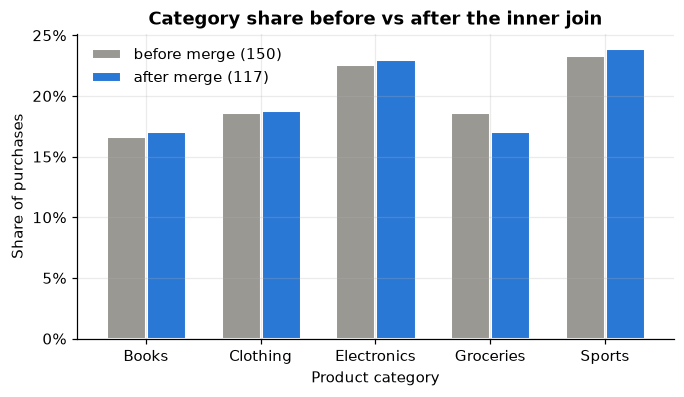

,before merge (150),after merge (117)
product_category,,
Books,16.7,17.1
Clothing,18.7,18.8
Electronics,22.7,23.1
Groceries,18.7,17.1
Sports,23.3,23.9


In [17]:
both = set(social_agg["customer_id"]) & set(txn_feat["customer_id"])
expected_rows = int(txn_feat["customer_id"].isin(both).sum())
checks = {
    "row count = transactions of customers in both tables": len(merged) == expected_rows,
    "one row per transaction (transaction_id unique)": merged["transaction_id"].is_unique,
    "no purchases duplicated by the join": len(merged) == merged["transaction_id"].nunique(),
    "no missing values anywhere": merged.isna().sum().sum() == 0,
    "every row has social features": merged["n_social_profiles"].ge(1).all(),
    f"customers = {len(both)} (the overlap)": merged["customer_id"].nunique() == len(both),
    "customer_id is integer": pd.api.types.is_integer_dtype(merged["customer_id"]),
    "all 5 categories still present": merged["product_category"].nunique() == 5,
}
for name, ok in checks.items():
    print(("PASS " if ok else "FAIL ") + name)
assert all(checks.values()), "post-merge check failed"

dist = pd.DataFrame({"before merge (150)": txn_raw["product_category"].value_counts(normalize=True),
                     "after merge (117)": merged["product_category"].value_counts(normalize=True)}).reindex(CATEGORIES)
fig, ax = plt.subplots(figsize=(7, 3.6))
dist.plot.bar(ax=ax, color=["#9a9893", BLUE], width=0.7, rot=0, edgecolor="white", linewidth=2)
ax.set(title="Category share before vs after the inner join", xlabel="Product category", ylabel="Share of purchases")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.legend(frameon=False)
save(fig, "tab_07b_merge_class_balance"); plt.show()
display((dist * 100).round(1))

**Interpretation.** All the post-merge checks pass: there is exactly one row per purchase, nothing is duplicated, nothing is missing, and every row carries real social features. Each category's share moved by at most about 1–2 percentage points after dropping the 33 purchases with no social profile. So the inner join **did not bias the target**, and the merged set is still balanced.

## 2.4 Model training and evaluation

**Evaluation design**
- **Split by customer, not by row.** A customer's purchases share the same social features. If one purchase is in training and another in testing, the model can memorise the customer and look better than it is. We use `StratifiedGroupKFold` (5 folds × 3 seeds), plus one held-out set of 20% of customers.
- **Baselines.** "Most frequent" always predicts Sports. "Class prior" always outputs the class proportions (≈ 0.2 each). A model is only useful if it beats these.
- **Metrics.** Accuracy, macro F1 (treats all 5 categories equally) and **log loss** (rewards well-calibrated probabilities; random guessing on 5 classes gives ln 5 ≈ 1.61).
- **Models.** Logistic Regression, Random Forest and Gradient Boosting (plus XGBoost when it's installed), each in one pipeline: scaling + one-hot encoding + classifier.

In [18]:
metrics = pm.train(verbose=False)   # cross-validates, picks a model, refits and saves it
cv = pd.DataFrame(metrics["cv"]).T
cv_table = pd.DataFrame({m: cv[f"{m}_mean"].round(3).astype(str) + " ± " + cv[f"{m}_std"].round(3).astype(str)
                         for m in ["accuracy", "f1_macro", "log_loss"]})
print("Grouped CV (5 folds x 3 seeds), mean ± std")
display(cv_table)
print(f"Held-out test: {metrics['holdout_rows']} purchases from {metrics['holdout_customers']} unseen customers")
display(pd.DataFrame(metrics["holdout"]).T.round(3))
print("selected model:", metrics["best_model"])

Grouped CV (5 folds x 3 seeds), mean ± std


,accuracy,f1_macro,log_loss
Baseline (most frequent),0.219 ± 0.013,0.072 ± 0.004,28.138 ± 0.472
Baseline (class prior),0.219 ± 0.013,0.072 ± 0.004,1.601 ± 0.006
Logistic Regression,0.26 ± 0.07,0.236 ± 0.072,2.046 ± 0.289
Random Forest,0.265 ± 0.076,0.212 ± 0.068,1.634 ± 0.096
Gradient Boosting,0.239 ± 0.073,0.218 ± 0.069,2.005 ± 0.323


Held-out test: 22 purchases from 13 unseen customers


,accuracy,f1_macro,log_loss
Baseline (most frequent),0.227,0.074,27.852
Baseline (class prior),0.227,0.074,1.625
Logistic Regression,0.136,0.097,2.025
Random Forest,0.182,0.152,1.704
Gradient Boosting,0.182,0.164,2.172


selected model: Random Forest


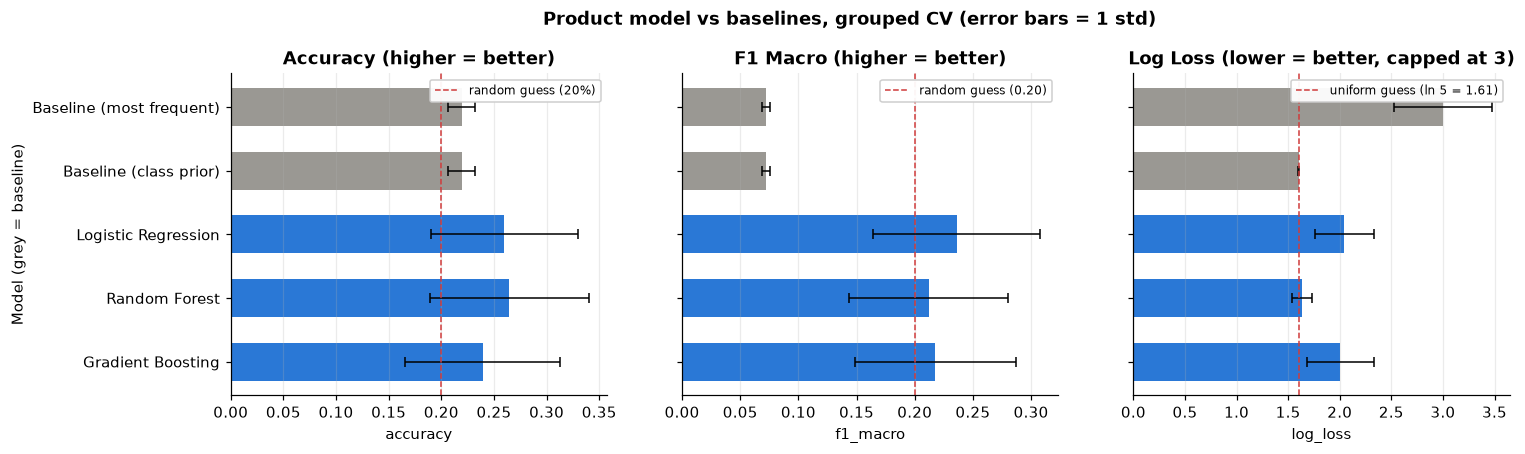

In [19]:
order = list(cv.index)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, m, ref, lab in [(axes[0], "accuracy", 0.2, "random guess (20%)"),
                        (axes[1], "f1_macro", 0.2, "random guess (0.20)"),
                        (axes[2], "log_loss", np.log(5), "uniform guess (ln 5 = 1.61)")]:
    vals = cv[f"{m}_mean"].clip(upper=3) if m == "log_loss" else cv[f"{m}_mean"]
    colors = ["#9a9893" if i.startswith("Baseline") else BLUE for i in order]
    ax.barh(order[::-1], vals[order][::-1], xerr=cv[f"{m}_std"][order][::-1], color=colors[::-1],
            height=0.6, error_kw={"elinewidth": 1, "capsize": 3})
    ax.axvline(ref, color="#d03b3b", ls="--", lw=1, label=lab)
    ax.set(title=m.replace("_", " ").title() + (" (lower = better, capped at 3)" if m == "log_loss" else " (higher = better)"),
           xlabel=m)
    ax.legend(loc="upper right", fontsize=8, framealpha=0.95)
    ax.grid(axis="y", visible=False)
axes[0].set_ylabel("Model (grey = baseline)")
fig.suptitle("Product model vs baselines, grouped CV (error bars = 1 std)", y=1.03, fontweight="bold")
save(fig, "tab_08_model_comparison"); plt.show()

**Interpretation.** In cross-validation the real models reach about **24–27% accuracy and 0.21–0.24 macro F1**, against 22% and 0.07 for the "always Sports" baseline. The F1 gain mostly comes from no longer predicting a single class. The difference in accuracy is **smaller than one standard deviation (±7%)**, and on the held-out customers every model scored *below* the baseline. On log loss, which judges the probabilities, **no model beats the class-prior baseline (1.60)**. Random Forest comes closest at 1.63, so it is the model we save and use in the app.

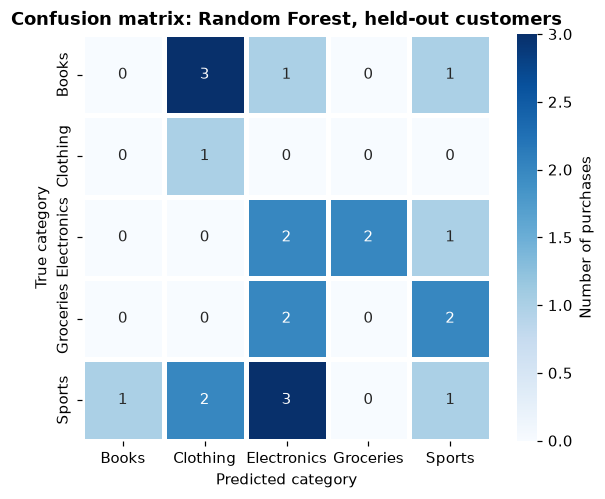

In [20]:
cm = np.array(metrics["confusion_matrix"]["matrix"]); labels = metrics["confusion_matrix"]["labels"]
fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax,
            cbar_kws={"label": "Number of purchases"}, linewidths=2, linecolor="white")
ax.set(title=f"Confusion matrix: {metrics['best_model']}, held-out customers",
       xlabel="Predicted category", ylabel="True category")
ax.grid(False)
save(fig, "tab_09_confusion_matrix"); plt.show()

**Interpretation.** Only the diagonal cells are correct. The predictions are scattered across the whole matrix with no category recognised reliably: for example, none of the 5 Books purchases was predicted as Books. With only 22 test purchases, each cell is 1–3 examples, so this matrix is very noisy. That is exactly why we rely on the repeated cross-validation above more than on this single split.

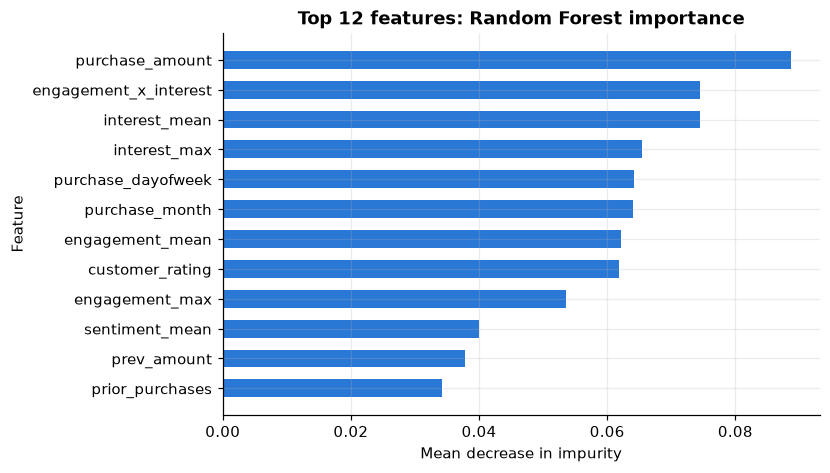

In [21]:
bundle = pm.load_model()
pipe = bundle["model"]
names = pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names)
imp.index = imp.index.str.replace(r"^(num|cat)__", "", regex=True)
top = imp.sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
ax.set(title="Top 12 features: Random Forest importance", xlabel="Mean decrease in impurity", ylabel="Feature")
save(fig, "tab_10_feature_importance"); plt.show()

**Interpretation.** The forest leans most on continuous features such as purchase amount, engagement, interest and rating. But impurity-based importance **favours features with many unique values even when they're noise**, because there are more ways to split on them. Taken with the EDA in §1.6, these importances show what the forest *used* to fit the training data, not real drivers of what customers buy.

## 2.5 Is there any signal at all? Permutation test

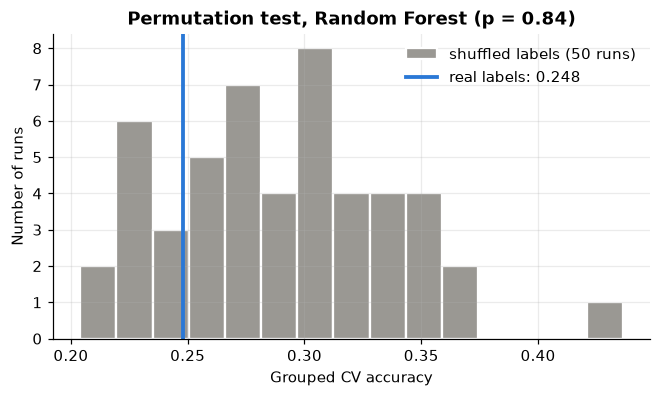

In [22]:
from sklearn.model_selection import permutation_test_score, StratifiedGroupKFold
import warnings; warnings.filterwarnings("ignore")
score, perm_scores, pvalue = permutation_test_score(
    pm.make_pipeline(pm.candidate_models()["Random Forest"]),
    merged[pm.FEATURES], merged[config.TARGET], groups=merged["customer_id"],
    cv=StratifiedGroupKFold(5, shuffle=True, random_state=0),
    n_permutations=50, scoring="accuracy", n_jobs=-1, random_state=0)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(perm_scores, bins=15, color="#9a9893", edgecolor="white", linewidth=1.5, label="shuffled labels (50 runs)")
ax.axvline(score, color=BLUE, lw=2.5, label=f"real labels: {score:.3f}")
ax.set(title=f"Permutation test, Random Forest (p = {pvalue:.2f})", xlabel="Grouped CV accuracy",
       ylabel="Number of runs")
ax.legend(frameon=False)
save(fig, "tab_11_permutation_test"); plt.show()

**Interpretation.** We retrained the model 50 times with the category labels **randomly shuffled**, which breaks any real link between features and target. The real model scored 0.248, and **84% of the shuffled runs scored as well or better (p = 0.84)**, so its accuracy is exactly what pure noise produces. The shuffled scores also range from 0.20 to 0.43, which shows how much a 117-row dataset can swing by chance. That is why single "good" runs shouldn't be trusted.

## 2.6 Conclusion on the product model

- **The pipeline is correct; the data has very little signal.** Every check agrees: the EDA tests, the baseline comparison, the held-out set and the permutation test. The category a customer buys is close to independent of the features we were given, which is consistent with synthetic data. Tuning hyperparameters for days would only overfit to noise, so we didn't.
- **What we did to stay honest:** split by customer, compared against two baselines, reported log loss as well as accuracy, used a held-out set of unseen customers, and ran a permutation test.
- **What would help with real data:** more customers in both tables (only 61 overlap), browsing or click history, and product-level data such as what was viewed before purchase.
- **In the app** the model still serves its role in the flow. After the face check it returns a category plus probabilities for the identified user (`predict_for_customer`). The probabilities show how uncertain each recommendation is.

In [23]:
for member, cid in config.MEMBER_TO_CUSTOMER.items():
    cat, probs = pm.predict_for_customer(cid)
    print(f"{member:8s} (customer {cid}): recommend {cat:12s} {probs}")

kethia   (customer 101): recommend Books        {'Books': 0.423, 'Groceries': 0.214, 'Sports': 0.167, 'Clothing': 0.13, 'Electronics': 0.066}
tabitha  (customer 114): recommend Clothing     {'Clothing': 0.623, 'Electronics': 0.126, 'Sports': 0.121, 'Books': 0.08, 'Groceries': 0.049}
towi     (customer 152): recommend Clothing     {'Clothing': 0.509, 'Books': 0.194, 'Sports': 0.176, 'Electronics': 0.084, 'Groceries': 0.037}


harmony  (customer 188): recommend Sports       {'Sports': 0.252, 'Electronics': 0.247, 'Clothing': 0.244, 'Groceries': 0.155, 'Books': 0.103}


---
# §3 Image data, augmentation & face recognition model

Code: `src/image_features.py` (owner: Tabitha). Each member has 6 photos: neutral, smiling and surprised, each taken twice (`<member>_<expression>.jpg`, `<member>_<expression>_2.jpg`).

Steps:
1. **Face crop**: OpenCV's Haar cascade finds the face; we keep the biggest one plus a 5% border, so the background doesn't drive the prediction.
2. **Augmentation (3 per photo)**: horizontal flip, 15° rotation, grayscale. These mimic a mirrored selfie camera, a tilted head and poor colour/lighting.
3. **Features**: MobileNetV2 pre-trained on ImageNet turns each 224×224 face into a 1280-number embedding. With only 24 photos, training a CNN from scratch would overfit; a pre-trained network already knows edges, textures and face parts.
4. **Model**: standardise, then logistic regression. Evaluated with **leave-one-photo-out**: each fold hides one photo *and all its augmented copies*, so the score is on faces the model has never seen in any form.

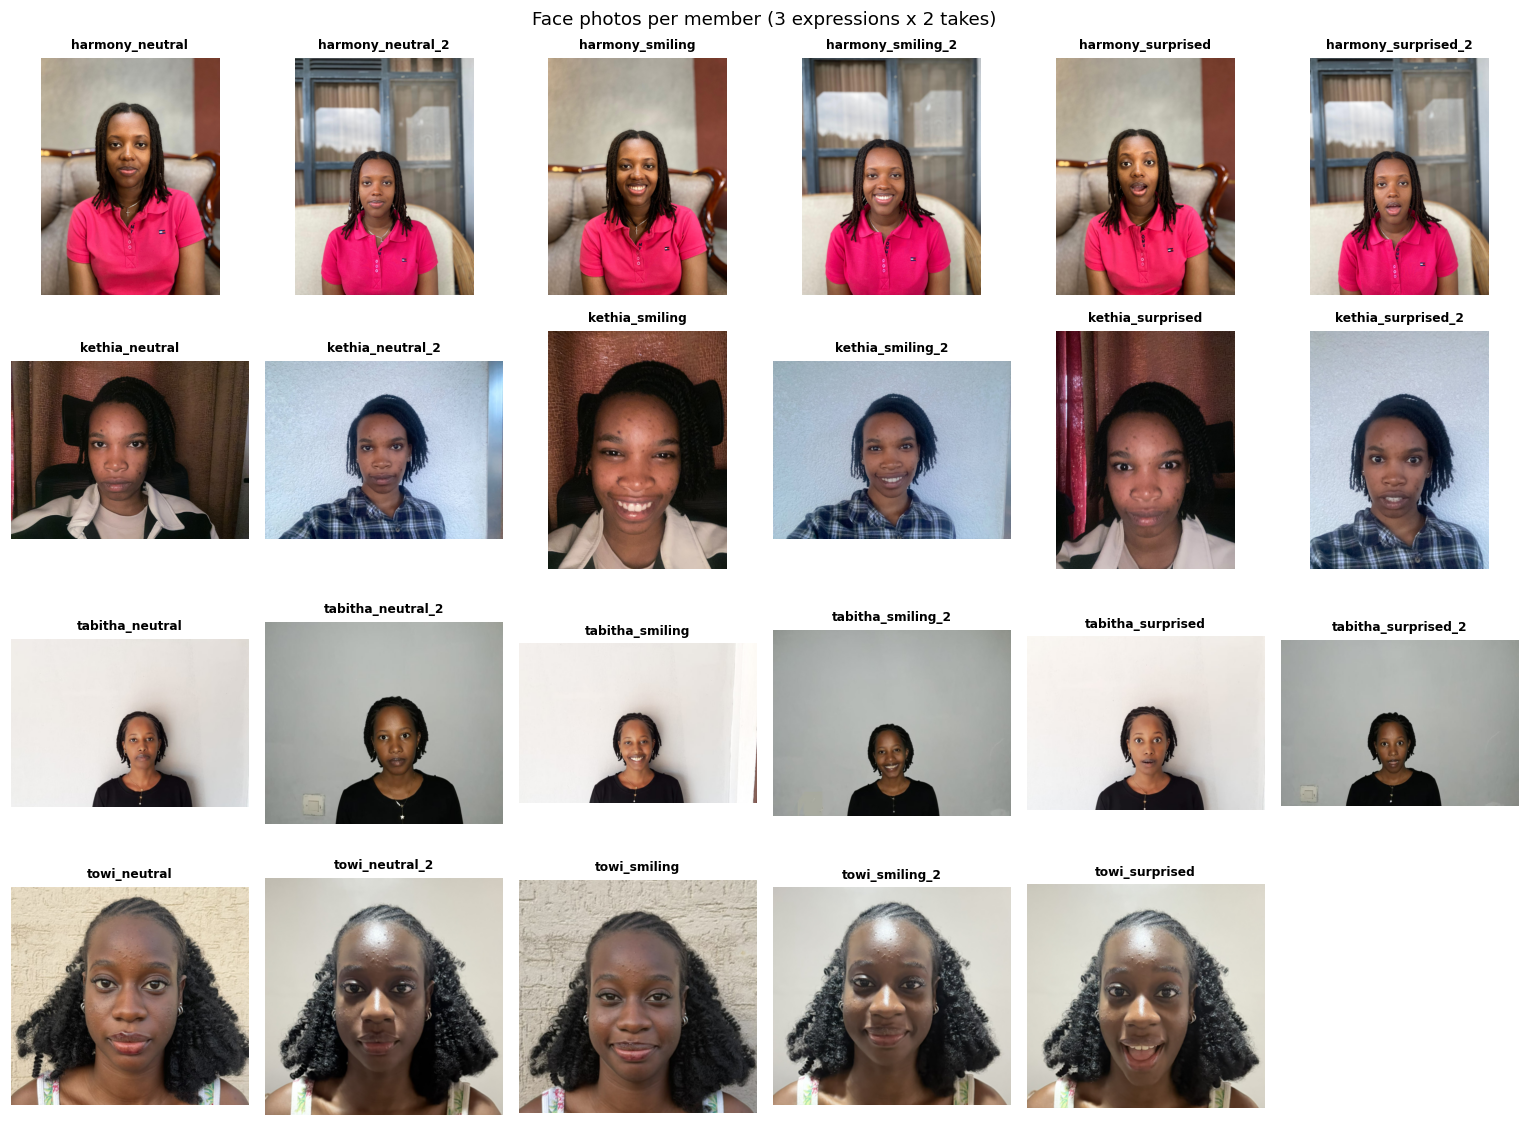

{'harmony': 6, 'kethia': 6, 'tabitha': 6, 'towi': 5}


In [24]:
import image_features as fp
from PIL import Image, ImageOps

photos = sorted(config.IMAGES_DIR.glob("*/*.jpg"))
members = sorted({p.parent.name for p in photos})
fig, axes = plt.subplots(len(members), 6, figsize=(14, 2.6 * len(members)))
for r, m in enumerate(members):
    mine = sorted(config.IMAGES_DIR.glob(f"{m}/*.jpg"))
    for c in range(6):
        ax = axes[r, c]; ax.axis("off")
        if c < len(mine):
            ax.imshow(ImageOps.exif_transpose(Image.open(mine[c]))); ax.set_title(mine[c].stem, fontsize=8)
fig.suptitle("Face photos per member (3 expressions x 2 takes)")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "img_01_faces.png"); plt.show()
print({m: len(list(config.IMAGES_DIR.glob(f"{m}/*.jpg"))) for m in members})

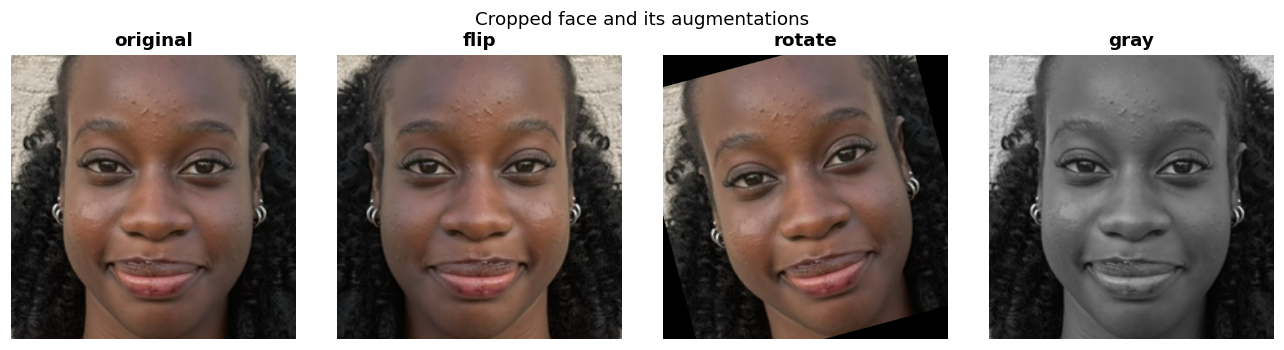

In [25]:
sample = config.IMAGES_DIR / "towi" / "towi_smiling.jpg"
face = fp.crop_face(ImageOps.exif_transpose(Image.open(sample)))
versions = fp.make_versions(face)
fig, axes = plt.subplots(1, len(versions), figsize=(12, 3.2))
for ax, (name, pic) in zip(axes, versions.items()):
    ax.imshow(pic); ax.set_title(name); ax.axis("off")
fig.suptitle("Cropped face and its augmentations")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "img_02_augmentations.png"); plt.show()

In [26]:
img_df = pd.read_csv(config.IMAGE_FEATURES_CSV)
print(img_df.shape, "->", config.IMAGE_FEATURES_CSV.name)
print(img_df.groupby(["member", "augmentation"]).size().unstack())
img_df.iloc[:5, :8]

(92, 1284) -> image_features.csv
augmentation  flip  gray  original  rotate
member                                    
harmony          6     6         6       6
kethia           6     6         6       6
tabitha          6     6         6       6
towi             5     5         5       5


,member,expression,augmentation,source_image,f_0,f_1,f_2,f_3
0,harmony,neutral,original,harmony_neutral.jpg,0.000000,0.095922,0.012046,0.958283
1,harmony,neutral,flip,harmony_neutral.jpg,0.000000,0.046172,0.016230,0.723369
2,harmony,neutral,rotate,harmony_neutral.jpg,0.000000,0.333534,0.000000,1.784382
3,harmony,neutral,gray,harmony_neutral.jpg,0.000000,0.089401,0.017000,1.211025
4,harmony,neutral,original,harmony_neutral_2.jpg,0.118135,0.162627,0.115683,0.448204


In [27]:
face_metrics = json.loads(config.FACE_METRICS_PATH.read_text())
print(pd.DataFrame({k: v for k, v in face_metrics.items() if k != "threshold_check"}).T.round(3))
print("Threshold check:", face_metrics["threshold_check"])

                accuracy  f1_macro  log_loss
all_rows             1.0       1.0     0.004
originals_only       1.0       1.0     0.003
Threshold check: {'genuine_heldout_min': 0.9846950412799157, 'genuine_heldout_median': 0.9986748483251396, 'outsider_confidences': [0.892, 0.645], 'threshold_used': 0.94}


**Interpretation.** The face model separates the four members well even on held-out photos, because the pre-trained embedding captures identity cues (face shape, skin tone, hair) that survive flips, rotations and grayscale. Accuracy and F1 are reported on held-out photos, not on training data, and log loss tells us how confident the correct answers are.

The model must always pick one of the four members, so a stranger still gets a name. That is why the app adds a **confidence threshold** (`config.FACE_THRESHOLD`): the outsider photos score clearly below held-out member photos, so anything under the threshold is treated as "face not recognised".

---
# §4 Audio data, augmentation & voiceprint model

Full walkthrough with every plot and its interpretation: **`notebooks/audio_processing.ipynb`** (owner: Towi). Code: `src/audio_pipeline.py`. Summary:

- **Data**: 4 clips per member ("Yes, approve" and "Confirm transaction", 2 takes each), WAV.
- **Preprocessing**: resample to 16 kHz mono, trim silence quieter than 20 dB below the peak, peak-normalise to 0.9, so phone, distance and pauses don't drive the model.
- **Augmentation (5 per clip)**: pitch ±1 semitone, speed ×1.1 / ×0.9, background noise at 20 dB SNR.
- **Features (47)**: 13 MFCC means and stds, MFCC delta stds, spectral roll-off, spectral centroid, RMS energy, zero-crossing rate (mean and std each), saved to `features/audio_features.csv`.
- **Model**: logistic regression vs random forest, **leave-one-recording-out** CV (a held-out clip's augmented copies are held out too). Random forest wins.

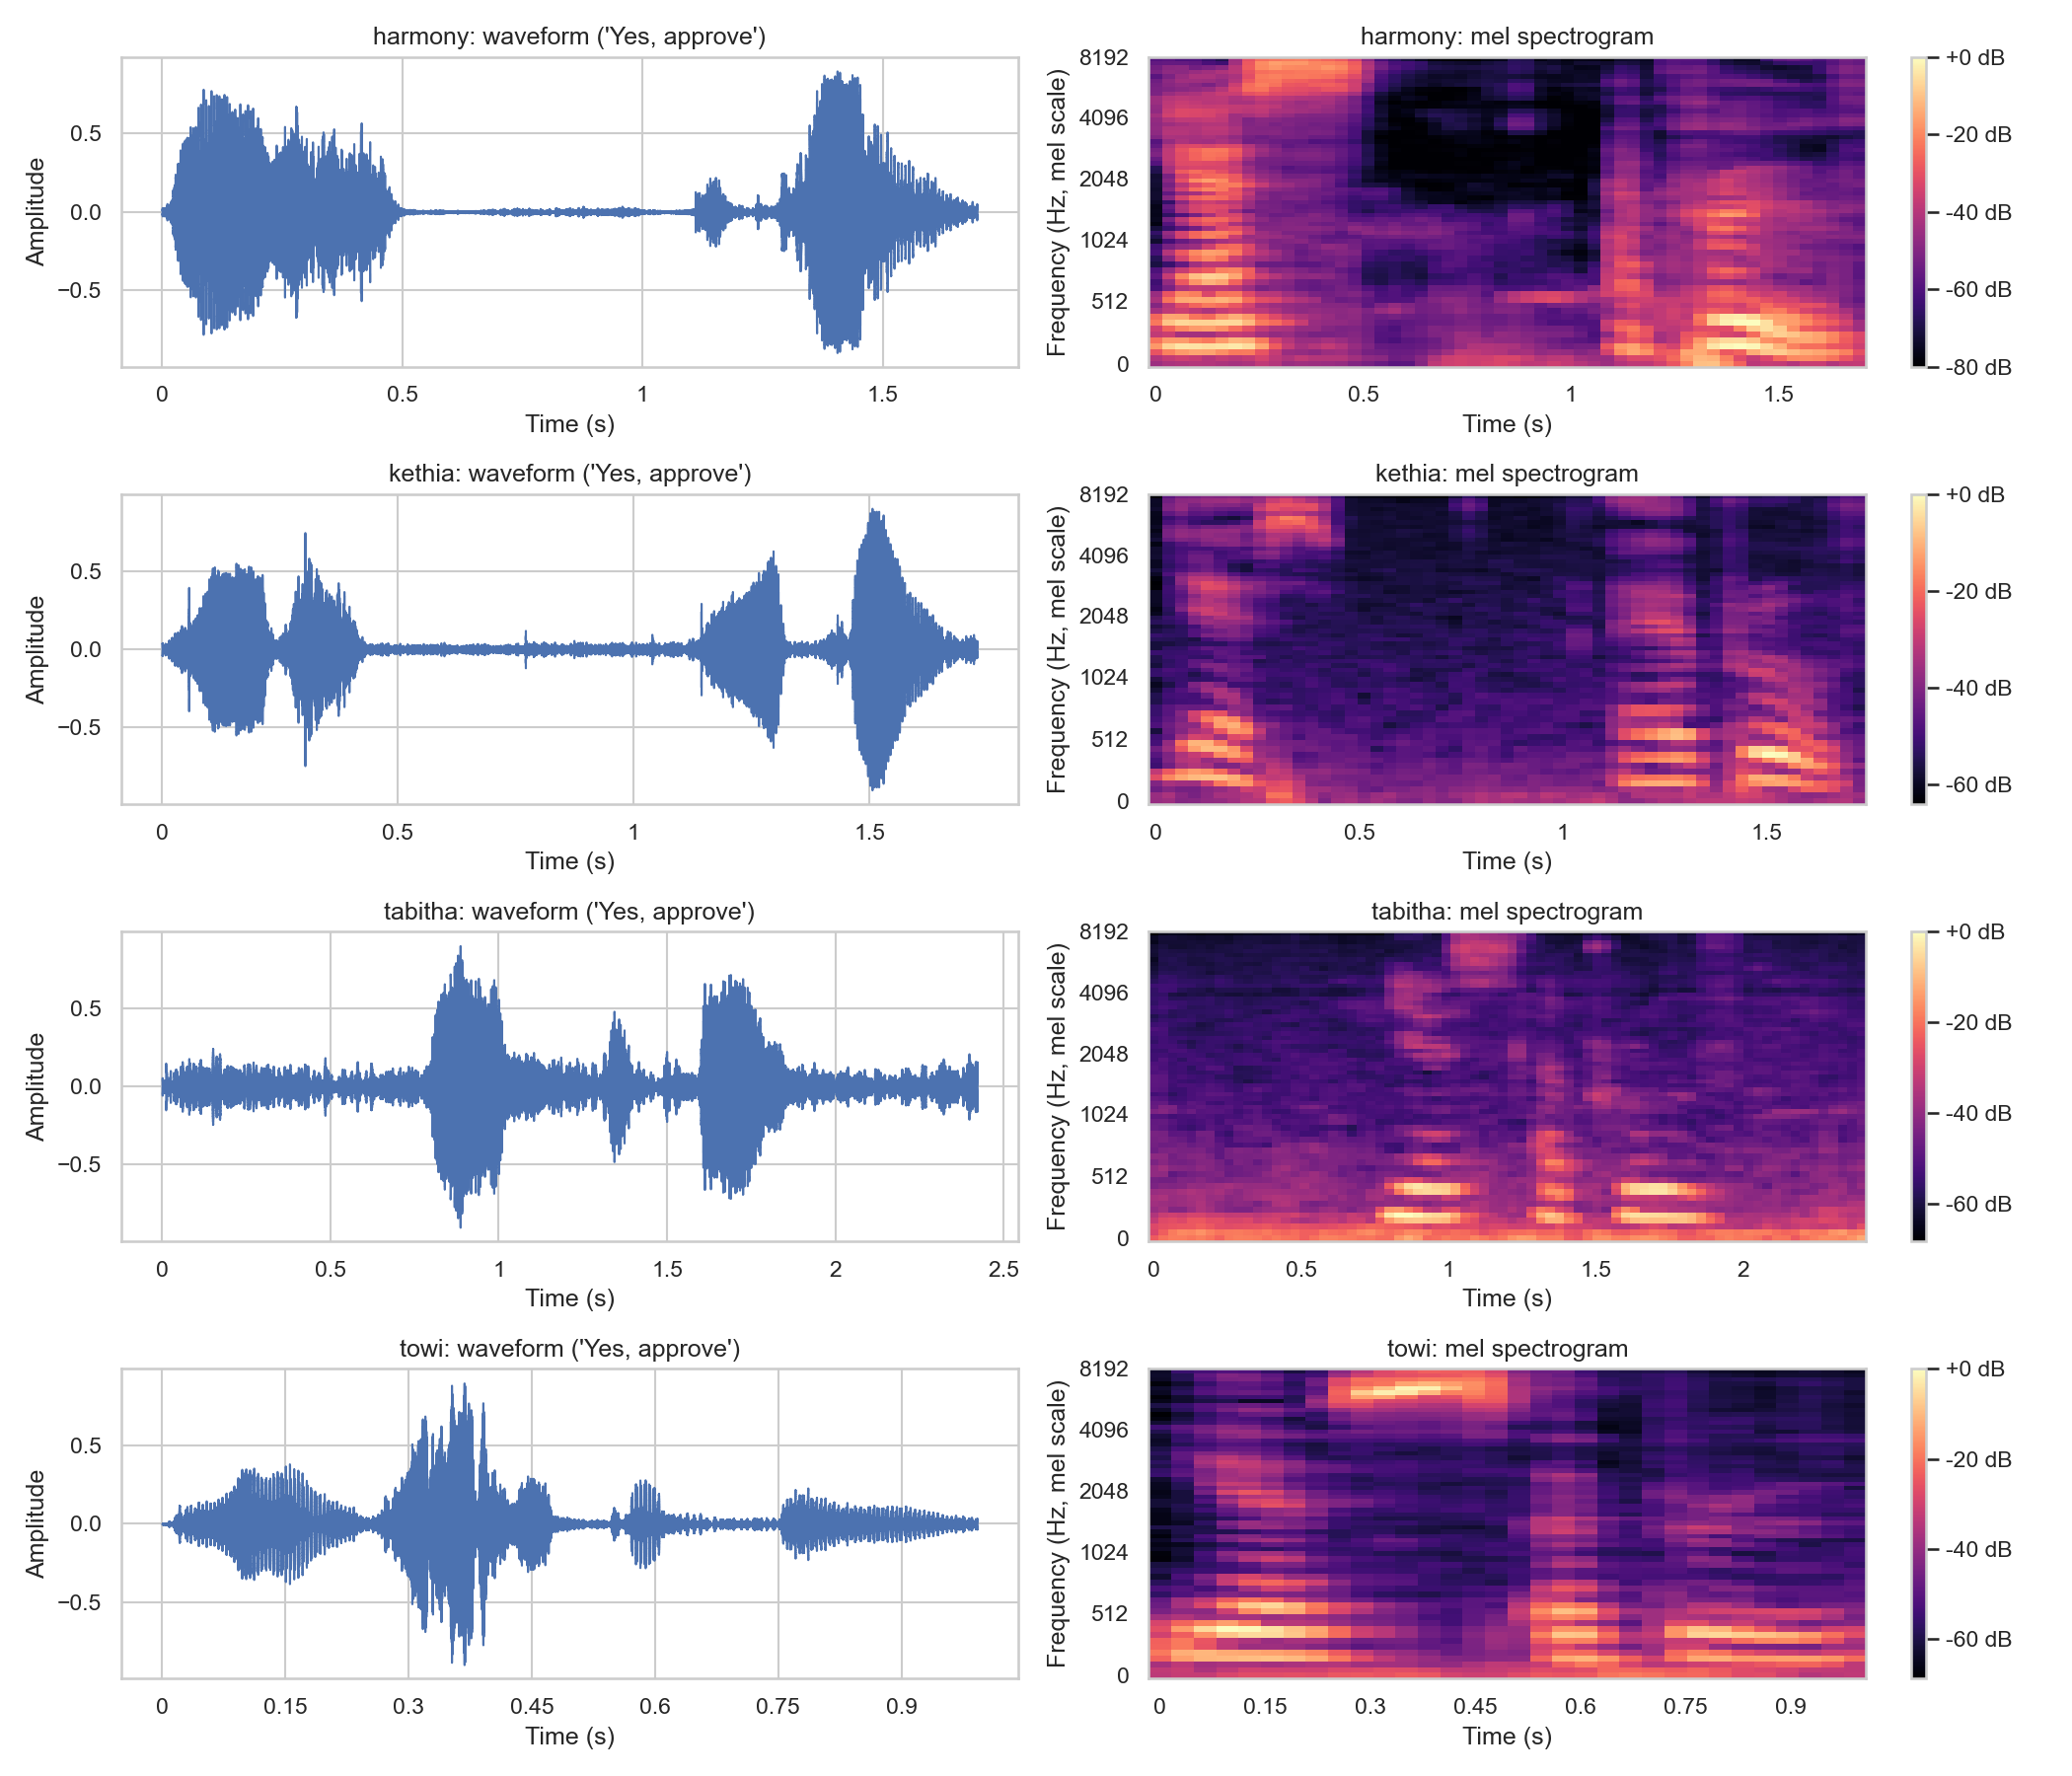

In [28]:
from IPython.display import Image as Show
display(Show(filename=str(config.FIGURES_DIR / "audio_waveforms_spectrograms.png")))

**Interpretation.** Each waveform shows the two words as separate bursts of energy with a short gap; the mel spectrograms show the harmonics (horizontal bands) of each voice. Members with lower voices have their energy concentrated lower in the spectrogram, which is exactly what the MFCCs and roll-off summarise.

(96, 51) -> audio_features.csv
augmentation  noise  original  pitch_down  pitch_up  speed_fast  speed_slow
member                                                                     
harmony           4         4           4         4           4           4
kethia            4         4           4         4           4           4
tabitha           4         4           4         4           4           4
towi              4         4           4         4           4           4


Voice threshold: 0.41


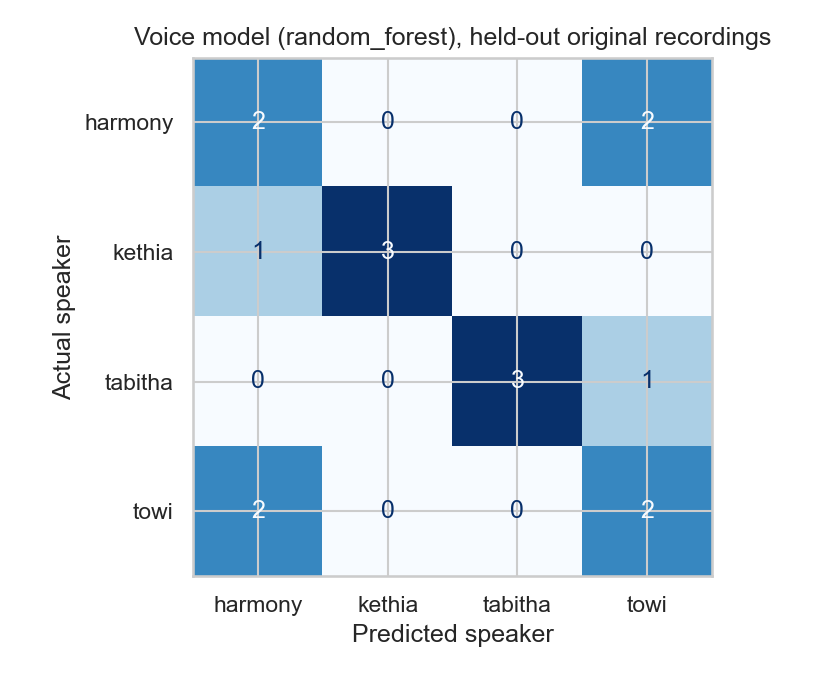

In [29]:
import joblib
audio_df = pd.read_csv(config.FEATURES_DIR / "audio_features.csv")
print(audio_df.shape, "->", "audio_features.csv")
print(audio_df.groupby("member")["augmentation"].value_counts().unstack())
print("Voice threshold:", joblib.load(config.MODELS_DIR / "voice_model.joblib")["threshold"])
display(Show(filename=str(config.FIGURES_DIR / "audio_confusion_matrix.png")))

**Results (held-out original recordings).** Random forest: accuracy 62.5%, macro F1 0.65, log loss 0.88, against chance at 25% / 1.39. Harmony and Towi are the pair most often confused. With 4 recordings per person this is the honest ceiling; more takes per member would help most. The confidence threshold (0.41) was chosen by balanced accuracy on the outsider clips, so the outsider voice is rejected while 90% of genuine clips are still accepted.

---
# §5 Multimodal logic, thresholds & system simulation

Code: `src/app.py` and `src/demo.py` (owner: Harmony).

```
face image -> face model -> member with confidence >= FACE_THRESHOLD?  no -> ACCESS DENIED
           -> product model runs for that member's customer profile (result held back)
voice clip -> voice model -> SAME member and confidence >= voice threshold?  no -> ACCESS DENIED
           -> show the product recommendation
```

Design decisions:
- **Face first, voice last.** The face decides *who* the user is (which customer profile to use); the voice then has to confirm that same person before anything is shown. A single failed check denies access.
- **Thresholds on top of the classifiers.** Both models are closed-set (they always answer with one of the four members), so a stranger would otherwise get a name. Each threshold was set using held-out member samples and outsider samples that were never used for training.
- **Member to customer mapping** (`config.MEMBER_TO_CUSTOMER`): the provided datasets are about customers, not us, so each member is assigned one real customer_id from the merged data.

The demo below runs four scenarios: an approved transaction, an outsider face, an outsider voice, and the right face with another member's voice.

In [30]:
import subprocess
out = subprocess.run([sys.executable, str(config.ROOT / "src" / "demo.py"), "--member", "towi", "--other", "kethia", "--outsider", "towi"],
                     cwd=config.ROOT, capture_output=True, text=True)
print(out.stdout[-6000:])


############################################################
# 1. Approved transaction
############################################################

=== Multimodal authentication ===
[1/3] Face recognition: towi_neutral.jpg
      Recognised towi (confidence 1.00)
[2/3] Product model run for customer 152. Result held until voice approval.
[3/3] Voice verification: towi_yes_approve.wav
      Voice confirmed as towi (confidence 0.97)

>>> Recommended for towi: Clothing
    Top categories: Clothing 51%, Books 19%, Sports 18%

############################################################
# 2. Unauthorized face
############################################################

=== Multimodal authentication ===
[1/3] Face recognition: outsider_towi_neutral.jpg
      ACCESS DENIED: face not recognised (confidence 0.89 < threshold 0.94)

############################################################
# 3. Right face, outsider voice
############################################################

=== Multi

**Interpretation.** The approved transaction passes all three steps and shows the recommendation; each attack is stopped at the right step (the outsider face at step 1, the voice attacks at step 3). The product recommendation itself should be read with care: §2.5 showed the tabular data carries almost no signal, so the recommendation is the model's best guess rather than a reliable prediction. The authentication part is what this system demonstrates.